In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, 
classification_report, confusion_matrix, accuracy_score, precision_score,
recall_score, f1_score, roc_auc_score, roc_curve, auc)
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor, 
    RandomForestClassifier)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import label_binarize

In [2]:
# load in data
scaled_path = Path('processed_merged_event_level_scaled.csv')
base_path = Path('processed_merged_event_level.csv')

df_scaled = pd.read_csv(scaled_path)
df_base = pd.read_csv(base_path)

print('Scaled shape:', df_scaled.shape)
print('Base shape:', df_base.shape)

X = df_scaled.drop(columns=['fatalities']).copy()
y_scaled = pd.to_numeric(df_scaled['fatalities'], errors='coerce')
y_count  = pd.to_numeric(df_base['fatalities'], errors='coerce')

Scaled shape: (154462, 23)
Base shape: (154462, 1563)


In [3]:
# train test split for models
indices = np.arange(len(X))

idx_train, idx_temp = train_test_split(indices, test_size=0.20,
                                       random_state=42)

idx_val, idx_test = train_test_split(idx_temp, test_size=0.50,
                                     random_state=42)

print('Train:', len(idx_train), 'Val:', len(idx_val), 'Test:', len(idx_test))

X_train = X.iloc[idx_train].copy()
X_val = X.iloc[idx_val].copy()
X_test = X.iloc[idx_test].copy()

y_train = y_count.iloc[idx_train].copy()
y_val = y_count.iloc[idx_val].copy()
y_test = y_count.iloc[idx_test].copy()


Train: 123569 Val: 15446 Test: 15447


In [4]:
# helper functions for regression metrics and plots
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2,}

def plot_regression_results(y_true, y_pred, title):
    _, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].scatter(y_true, y_pred, alpha=0.35, s=12)
    mn = min(np.min(y_true), np.min(y_pred))
    mx = max(np.max(y_true), np.max(y_pred))
    axes[0].plot([mn, mx], [mn, mx], linestyle='--')
    axes[0].set_title(f'{title}: Actual vs Predicted')
    axes[0].set_xlabel('Actual')
    axes[0].set_ylabel('Predicted')

    residuals = y_true - y_pred
    axes[1].hist(residuals, bins=40)
    axes[1].set_title(f'{title}: Residuals')
    axes[1].set_xlabel('Residual')
    axes[1].set_ylabel('Frequency')

    plt.tight_layout()
    plt.show()


def evaluate_and_plot(model_name, model, X_train, y_train, X_val,
                      y_val, X_test, y_test):
    model.fit(X_train, y_train)

    pred_val = model.predict(X_val)
    pred_test = model.predict(X_test)

    val_metrics = regression_metrics(y_val, pred_val)
    test_metrics = regression_metrics(y_test, pred_test)

    out = {'model': model_name,
        **{f'val_{k}': v for k, v in val_metrics.items()},
        **{f'test_{k}': v for k, v in test_metrics.items()},}

    print(f'\n--- {model_name} ---')
    print(pd.Series(out))
    plot_regression_results(y_test, pred_test, model_name)
    return out
results = []

## Linear Regression


--- Linear Regression ---
model        Linear Regression
val_MSE               73.05836
val_RMSE              8.547418
val_MAE               1.910947
val_R2                0.014149
test_MSE             68.871006
test_RMSE             8.298856
test_MAE              1.963226
test_R2                0.01673
dtype: object


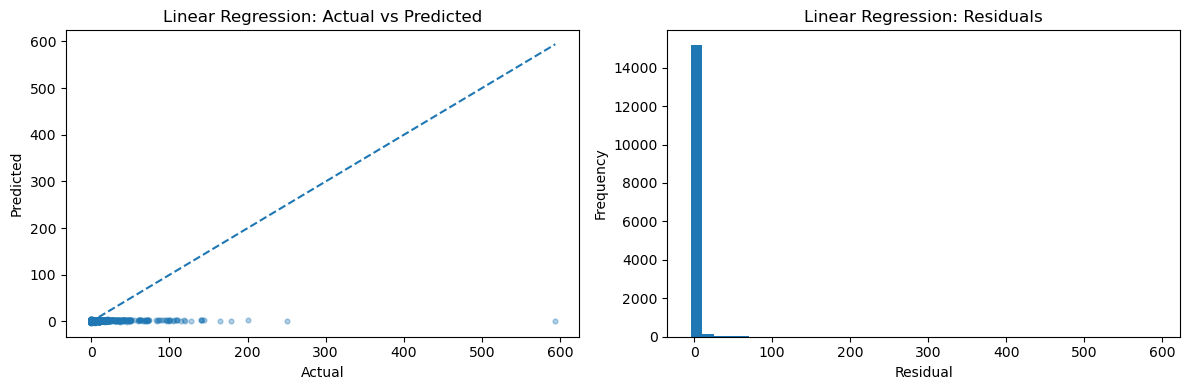

In [5]:
linreg_model = LinearRegression()
results.append(evaluate_and_plot('Linear Regression', linreg_model,
                                 X_train, y_train, X_val, y_val,
                                 X_test, y_test,))

## Elastic Net Regression


--- Elastic Net Regression ---
model        Elastic Net Regression
val_MSE                    73.10009
val_RMSE                   8.549859
val_MAE                    1.899246
val_R2                     0.013586
test_MSE                  68.855262
test_RMSE                  8.297907
test_MAE                   1.952313
test_R2                    0.016955
dtype: object


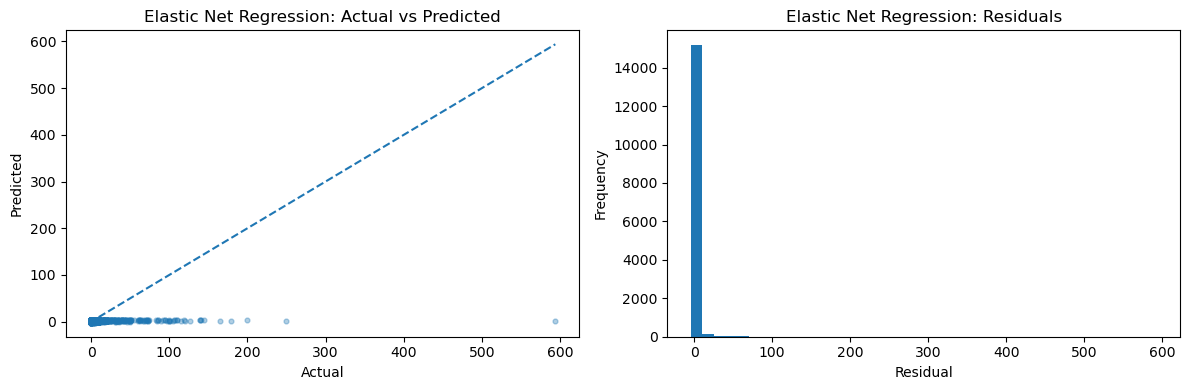

In [6]:
elastic_model = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000, random_state=42)
results.append(evaluate_and_plot('Elastic Net Regression', elastic_model,
                                 X_train, y_train, X_val, y_val, X_test,
                                 y_test,))

## Decision Tree Regressor


--- Decision Tree Regressor ---
model        Decision Tree Regressor
val_MSE                    68.071507
val_RMSE                    8.250546
val_MAE                     1.362943
val_R2                      0.081442
test_MSE                   61.694724
test_RMSE                   7.854599
test_MAE                    1.411488
test_R2                     0.119186
dtype: object


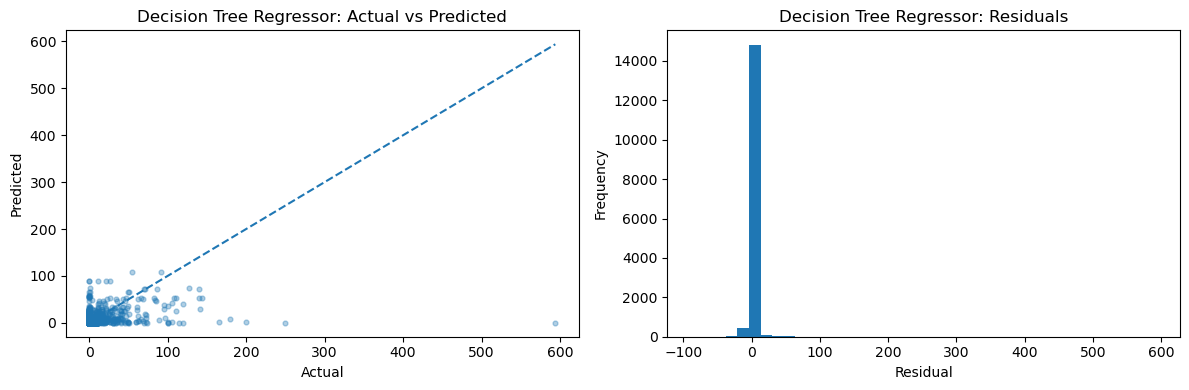

In [7]:
dt_model = DecisionTreeRegressor(max_depth=12, min_samples_leaf=10, random_state=42)
results.append(evaluate_and_plot('Decision Tree Regressor', dt_model, X_train,
                                 y_train, X_val, y_val, X_test, y_test,))

## Random Forest Regressor


--- Random Forest Regressor ---
model        Random Forest Regressor
val_MSE                    65.843307
val_RMSE                    8.114389
val_MAE                     1.282259
val_R2                      0.111509
test_MSE                   61.924724
test_RMSE                   7.869226
test_MAE                    1.331175
test_R2                     0.115902
dtype: object


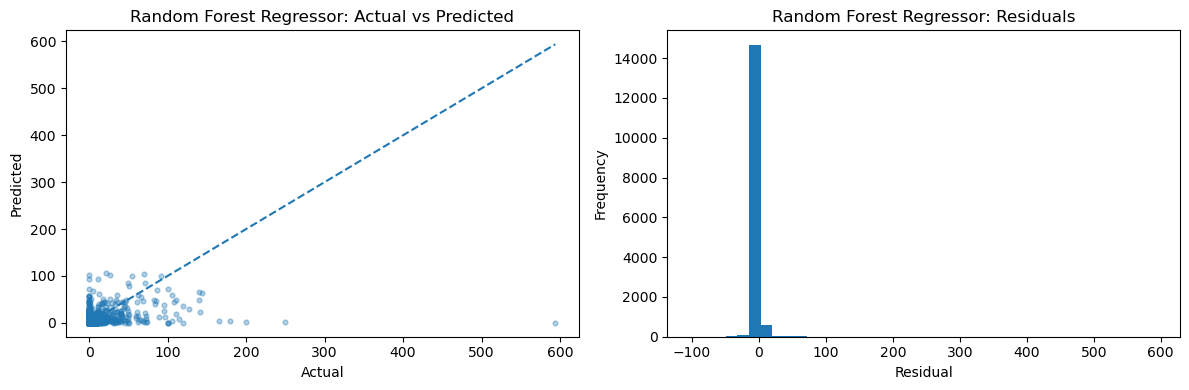

In [8]:
rf_model = RandomForestRegressor(n_estimators=300, max_depth=None,
                                 min_samples_leaf=3, n_jobs=-1,
                                 random_state=42,)
results.append(evaluate_and_plot('Random Forest Regressor', rf_model, X_train,
                                 y_train, X_val, y_val, X_test, y_test,))

## KNN Regressor


--- KNN Regressor ---
model        KNN Regressor
val_MSE          70.902974
val_RMSE           8.42039
val_MAE           1.364146
val_R2            0.043234
test_MSE         76.395232
test_RMSE         8.740437
test_MAE          1.443692
test_R2          -0.090693
dtype: object


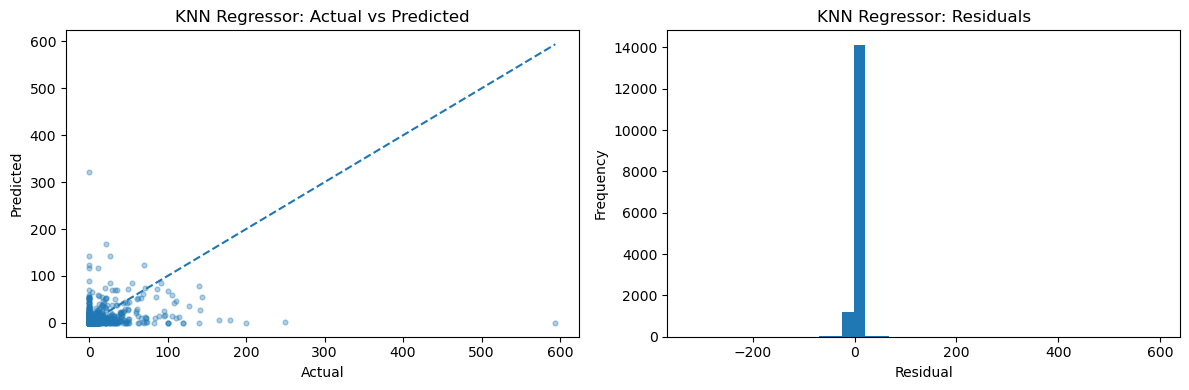

In [9]:
knn_model = KNeighborsRegressor(n_neighbors=15, weights='distance')
results.append(evaluate_and_plot('KNN Regressor', knn_model, X_train, y_train, 
                                 X_val, y_val, X_test, y_test,))

## Gradient Boosting Regressor


--- Gradient Boosting Regressor ---
model        Gradient Boosting Regressor
val_MSE                        63.750548
val_RMSE                        7.984394
val_MAE                         1.469774
val_R2                          0.139749
test_MSE                       59.407503
test_RMSE                       7.707626
test_MAE                        1.527799
test_R2                          0.15184
dtype: object


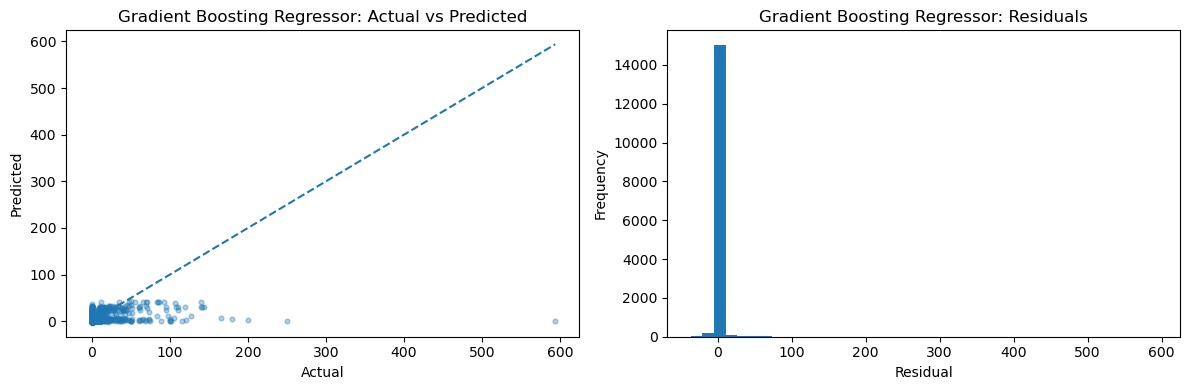

In [10]:
gb_model = GradientBoostingRegressor(random_state=42)
results.append(evaluate_and_plot('Gradient Boosting Regressor', gb_model,
                                 X_train,y_train, X_val, y_val, X_test,
                                 y_test,))

## XGBoost Regressor


--- XGBoost Regressor ---
model        XGBoost Regressor
val_MSE              71.149437
val_RMSE              8.435013
val_MAE                1.42315
val_R2                0.039908
test_MSE             63.574497
test_RMSE             7.973362
test_MAE               1.48042
test_R2               0.092348
dtype: object


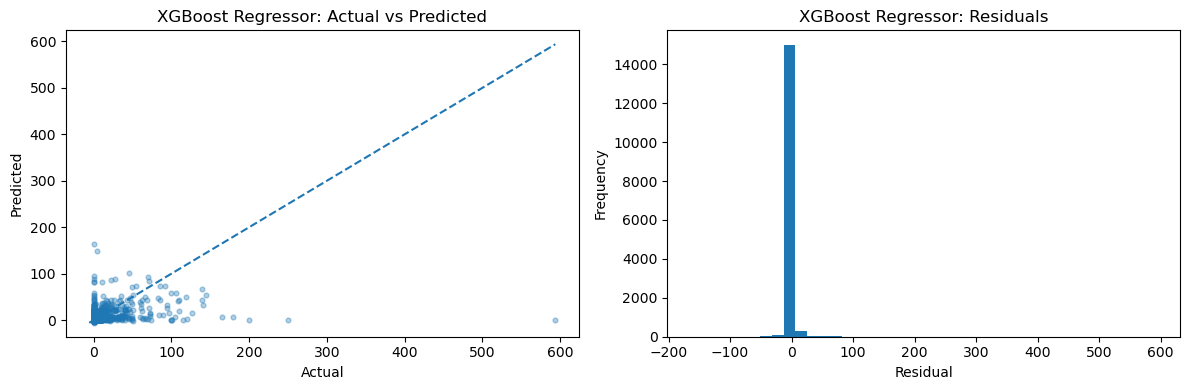

In [11]:
xgb_model = XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.05,
                         subsample=0.9, colsample_bytree=0.9, 
                         objective='reg:squarederror', random_state=42,
                         n_jobs=-1,)
results.append(evaluate_and_plot('XGBoost Regressor', xgb_model, X_train,
                                 y_train, X_val, y_val, X_test, y_test,))

## LightGBM Regressor

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001480 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3660
[LightGBM] [Info] Number of data points in the train set: 123569, number of used features: 22
[LightGBM] [Info] Start training from score 1.049843

--- LightGBM Regressor ---
model        LightGBM Regressor
val_MSE               62.768181
val_RMSE               7.922637
val_MAE                1.399795
val_R2                 0.153005
test_MSE              58.964902
test_RMSE              7.678861
test_MAE               1.459434
test_R2                0.158159
dtype: object


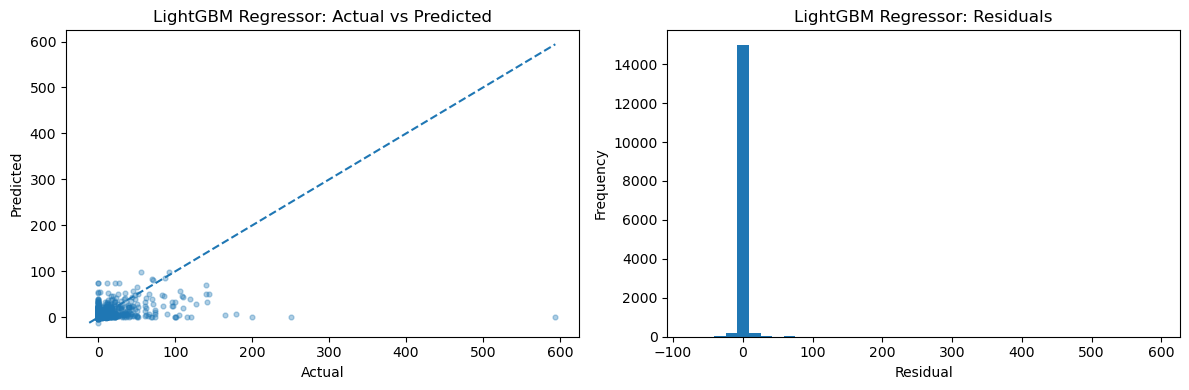

In [12]:
lgbm_model = LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                           subsample=0.9, colsample_bytree=0.9,
                           random_state=42,)
results.append(evaluate_and_plot('LightGBM Regressor', lgbm_model, X_train,
                                 y_train, X_val, y_val, X_test, y_test,))

## Neural Network Regressor


--- Neural Network Regressor ---
model        Neural Network Regressor
val_MSE                       64.2371
val_RMSE                     8.014805
val_MAE                      1.385481
val_R2                       0.133183
test_MSE                    59.308025
test_RMSE                     7.70117
test_MAE                      1.44025
test_R2                      0.153261
dtype: object


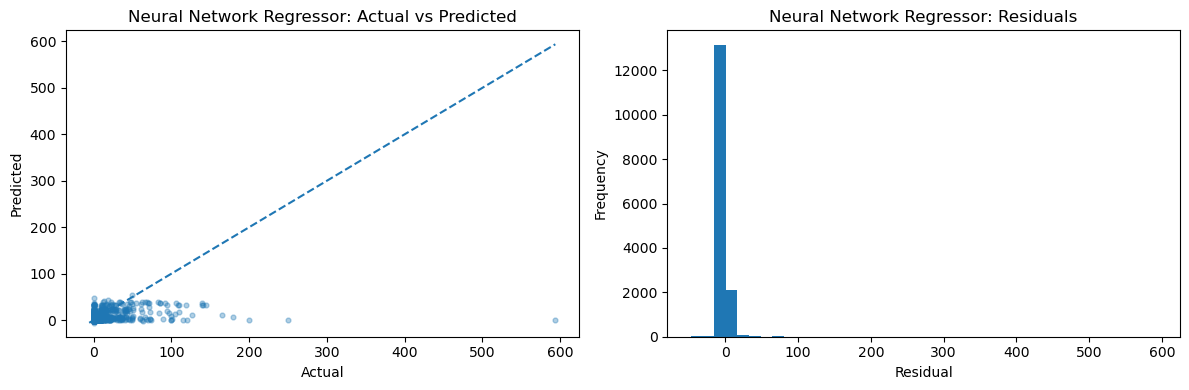

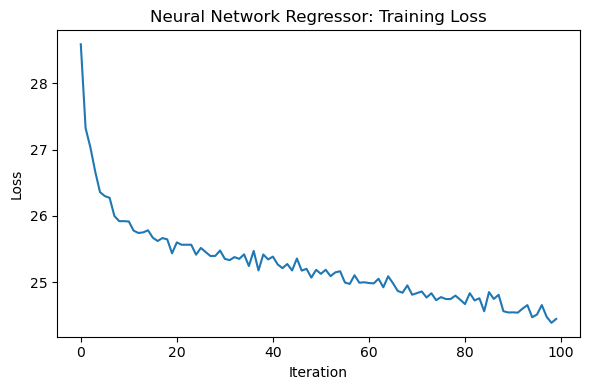

In [13]:
nn_model = MLPRegressor(hidden_layer_sizes=(256, 128, 64), activation='relu',
                        solver='adam', alpha=1e-4, batch_size=256,
                        learning_rate='adaptive', learning_rate_init=1e-3,
                        max_iter=300, early_stopping=True,
                        validation_fraction=0.1, n_iter_no_change=20,
                        random_state=42,)
results.append(evaluate_and_plot('Neural Network Regressor',nn_model, X_train,
                                 y_train, X_val, y_val, X_test, y_test,))

plt.figure(figsize=(6, 4))
plt.plot(nn_model.loss_curve_)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Neural Network Regressor: Training Loss')
plt.tight_layout()
plt.show()

## Results summary

In [14]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('test_RMSE', ascending=True).reset_index(drop=True)
results_df

,model,val_MSE,val_RMSE,val_MAE,val_R2,test_MSE,test_RMSE,test_MAE,test_R2
0,LightGBM Regressor,62.768181,7.922637,1.399795,0.153005,58.964902,7.678861,1.459434,0.158159
1,Neural Network Regressor,64.237100,8.014805,1.385481,0.133183,59.308025,7.701170,1.440250,0.153261
2,Gradient Boosting Regressor,63.750548,7.984394,1.469774,0.139749,59.407503,7.707626,1.527799,0.151840
3,Decision Tree Regressor,68.071507,8.250546,1.362943,0.081442,61.694724,7.854599,1.411488,0.119186
4,Random Forest Regressor,65.843307,8.114389,1.282259,0.111509,61.924724,7.869226,1.331175,0.115902
5,XGBoost Regressor,71.149437,8.435013,1.423150,0.039908,63.574497,7.973362,1.480420,0.092348
6,Elastic Net Regression,73.100090,8.549859,1.899246,0.013586,68.855262,8.297907,1.952313,0.016955
7,Linear Regression,73.058360,8.547418,1.910947,0.014149,68.871006,8.298856,1.963226,0.016730
8,KNN Regressor,70.902974,8.420390,1.364146,0.043234,76.395232,8.740437,1.443692,-0.090693


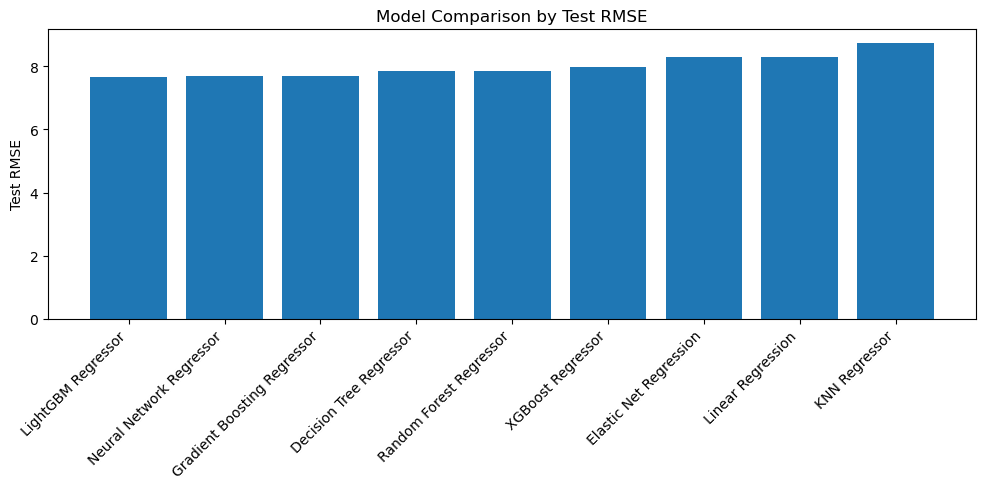

In [15]:
plt.figure(figsize=(10, 5))
plt.bar(results_df['model'], results_df['test_RMSE'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Test RMSE')
plt.title('Model Comparison by Test RMSE')
plt.tight_layout()
plt.show()

In [16]:
# bin fatalities into sensible ranges based on the data prevalence per class
bin_edges = [0, 1, 25, 50, 150, 300, np.inf]
range_labels = ["0", "1-25", "25-50", "50-150", "150-300", "300+",]

def bin_fatalities(values, edges):
    values = np.asarray(values, dtype=float)
    values = np.clip(values, 0, None)

    binned = pd.cut(values, bins=edges, labels=False, include_lowest=True,
                    right=False)

    # clip overflow
    binned = pd.Series(binned).fillna(len(edges) - 2).astype(int).to_numpy()
    return binned

# clean reload just in case
df_scaled = pd.read_csv(scaled_path)
df_class = df_scaled.copy()

# get target
y_raw = pd.to_numeric(df_class["fatalities"], errors="coerce").fillna(0)
X = df_class.drop(columns=["fatalities"])
# numeric only
X = X.select_dtypes(include=[np.number]).fillna(0)
# bin target
y_binned = bin_fatalities(y_raw, bin_edges)

# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y_binned, test_size=0.2,
                                                    random_state=42,
                                                    stratify=y_binned)

model = XGBClassifier(objective="multi:softprob", num_class=len(range_labels),
                      n_estimators=300, max_depth=6, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.8,
                      eval_metric="mlogloss", random_state=42)

model.fit(X_train, y_train)

# predict
y_pred = model.predict(X_test)

# eval
print("\n--- Classification Report for binned fatalities ---")
print(classification_report(y_test, y_pred, target_names=range_labels,
                            zero_division=0))

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))


--- Classification Report for binned fatalities ---
              precision    recall  f1-score   support

           0       0.88      0.98      0.93     26205
        1-25       0.61      0.20      0.30      4431
       25-50       0.38      0.16      0.23       142
      50-150       0.42      0.27      0.33       100
     150-300       0.00      0.00      0.00        12
        300+       0.00      0.00      0.00         3

    accuracy                           0.86     30893
   macro avg       0.38      0.27      0.30     30893
weighted avg       0.83      0.86      0.83     30893


--- Confusion Matrix ---
[[25691   487     9    18     0     0]
 [ 3529   873    17    10     2     0]
 [   67    42    23    10     0     0]
 [   42    20    11    27     0     0]
 [   11     1     0     0     0     0]
 [    2     1     0     0     0     0]]



---Model Comparison Summary ---


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,ROC AUC Macro OVR,ROC AUC Weighted OVR
0,Random Forest,0.8611,0.3322,0.2735,0.2933,0.8381,0.8611,0.8421,0.7387,0.8570
1,LightGBM,0.8608,0.3656,0.2829,0.3053,0.8372,0.8608,0.8338,0.8161,0.8626
2,XGBoost,0.8615,0.3812,0.2682,0.2964,0.8337,0.8615,0.8295,0.8989,0.8671


XGBoost — Classification Report
              precision    recall  f1-score   support

           0       0.88      0.98      0.93     26205
        1-25       0.61      0.20      0.30      4431
       25-50       0.38      0.16      0.23       142
      50-150       0.42      0.27      0.33       100
     150-300       0.00      0.00      0.00        12
        300+       0.00      0.00      0.00         3

    accuracy                           0.86     30893
   macro avg       0.38      0.27      0.30     30893
weighted avg       0.83      0.86      0.83     30893

Random Forest — Classification Report
              precision    recall  f1-score   support

           0       0.89      0.96      0.92     26205
        1-25       0.58      0.30      0.40      4431
       25-50       0.29      0.20      0.23       142
      50-150       0.24      0.18      0.21       100
     150-300       0.00      0.00      0.00        12
        300+       0.00      0.00      0.00         3

    acc

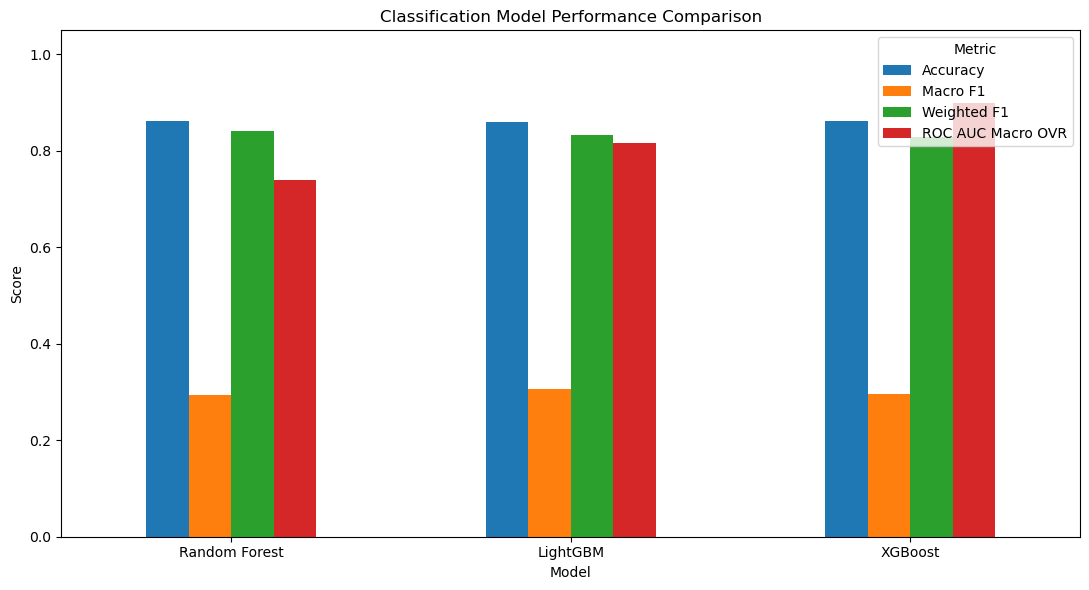

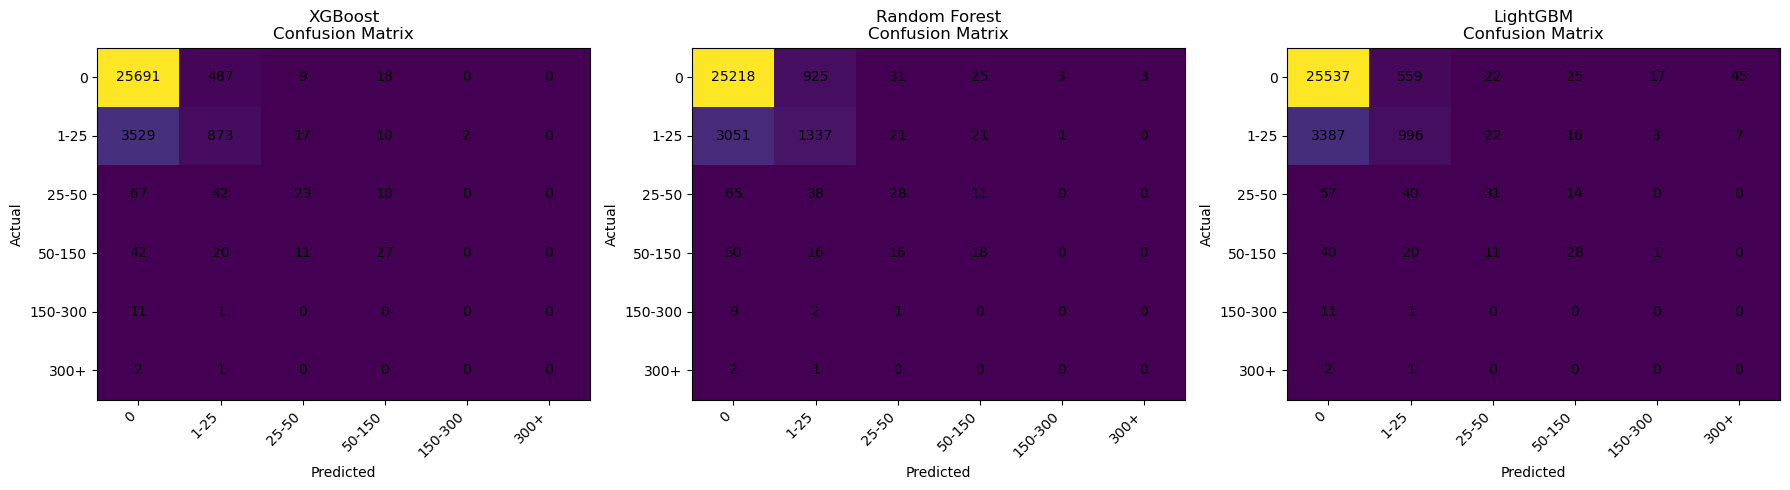

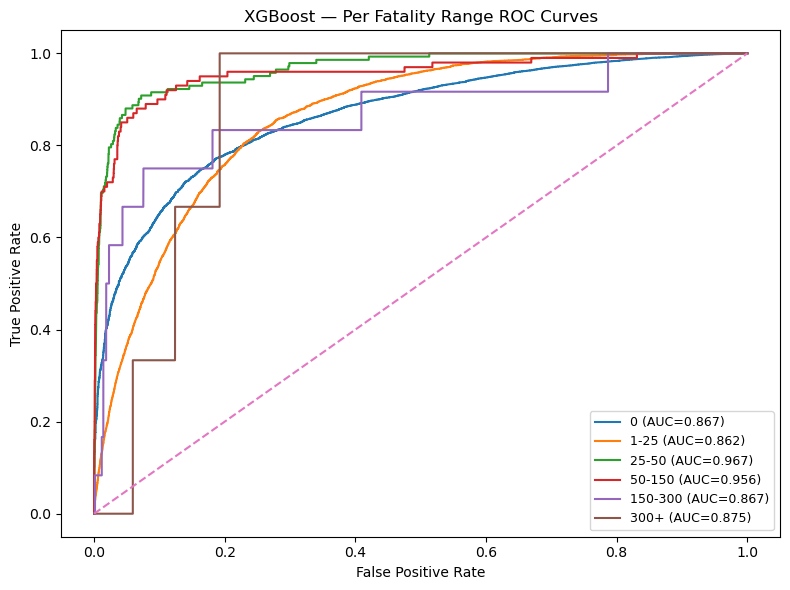

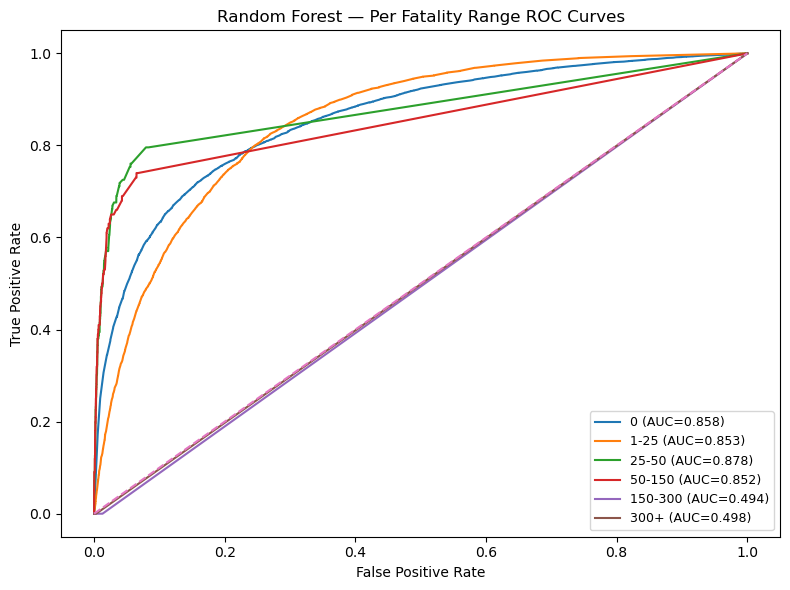

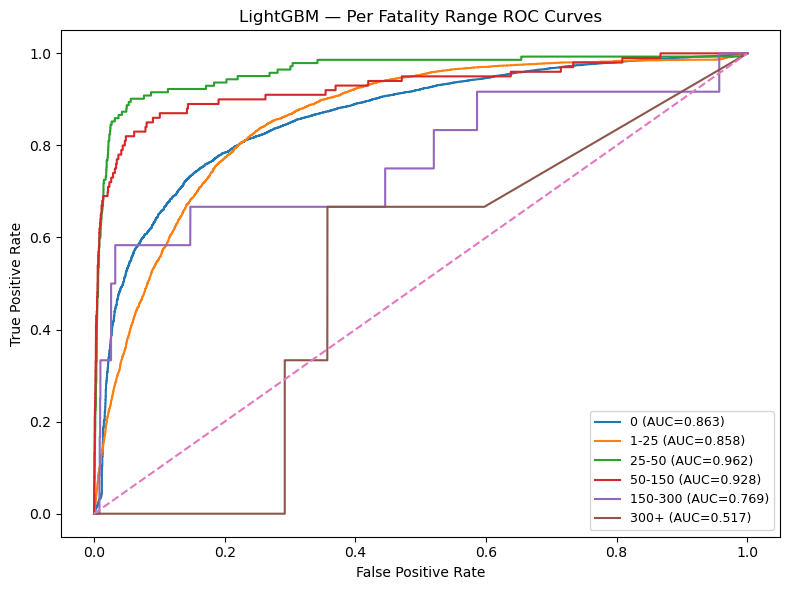

train =  0    104820
1     17724
2       568
3       398
4        47
5        12
Name: count, dtype: int64
test =  0    26205
1     4431
2      142
3      100
4       12
5        3
Name: count, dtype: int64


In [17]:
all_labels = list(range(len(range_labels)))
y_test_bin = label_binarize(y_test, classes=all_labels)

# make models
models = {"XGBoost": XGBClassifier(objective="multi:softprob", 
                                   num_class=len(range_labels),
                                   n_estimators=300, max_depth=6,
                                   learning_rate=0.05, subsample=0.8,
                                   colsample_bytree=0.8,
                                   eval_metric="mlogloss", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=None,
                                            min_samples_split=2,
                                            min_samples_leaf=1,
                                            class_weight="balanced_subsample",
                                            random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(objective="multiclass",
                               num_class=len(range_labels), n_estimators=300,
                               max_depth=-1, learning_rate=0.05, subsample=0.8,
                               colsample_bytree=0.8, random_state=42,
                               verbose=-1)}

# metrics and eval
results = []
stored_outputs = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)
    report = classification_report(y_test, y_pred, labels=all_labels,
                                   target_names=range_labels, zero_division=0,
                                   output_dict=True)

    cm = confusion_matrix(y_test, y_pred, labels=all_labels)

    # auc per class
    roc_auc_macro_ovr = roc_auc_score(y_test_bin, y_proba, multi_class="ovr",
                                  average="macro")


    roc_auc_weighted_ovr = roc_auc_score(y_test_bin, y_proba,
                                         multi_class="ovr", average="weighted")

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(y_test, y_pred,
                                           average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, y_pred,
                                     average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, y_pred,
                             average="macro", zero_division=0),
        "Weighted Precision": precision_score(y_test, y_pred,
                                              average="weighted",
                                              zero_division=0),
        "Weighted Recall": recall_score(y_test, y_pred,
                                        average="weighted", zero_division=0),
        "Weighted F1": f1_score(y_test, y_pred,
                                average="weighted", zero_division=0),
        "ROC AUC Macro OVR": roc_auc_macro_ovr,
        "ROC AUC Weighted OVR": roc_auc_weighted_ovr
    })

    stored_outputs[name] = {"model": model, "y_pred": y_pred,
                            "y_proba": y_proba, "report": report, "cm": cm}

results_df = pd.DataFrame(results).sort_values(
    "Weighted F1",ascending=False).reset_index(drop=True)

print("\n---Model Comparison Summary ---")
display(results_df.round(4))

# classification reports
for name in models.keys():
    print(f"{name} — Classification Report")
    print(classification_report(y_test, stored_outputs[name]["y_pred"],
                                labels=all_labels, target_names=range_labels,
                                zero_division=0))

# compare models
plot_df = results_df.set_index("Model")[["Accuracy", "Macro F1",
                                         "Weighted F1", "ROC AUC Macro OVR"]]

ax = plot_df.plot(kind="bar", figsize=(11, 6))
ax.set_title("Classification Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

# confusion matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, models.keys()):
    cm = stored_outputs[name]["cm"]
    im = ax.imshow(cm, aspect="auto")
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks(range(len(range_labels)))
    ax.set_xticklabels(range_labels, rotation=45, ha="right")
    ax.set_yticks(range(len(range_labels)))
    ax.set_yticklabels(range_labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

fig.tight_layout()
plt.show()

# roc for each class
for name in models.keys():
    y_proba = stored_outputs[name]["y_proba"]
    plt.figure(figsize=(8, 6))
    auc_values = []
    for i, class_name in enumerate(range_labels):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        roc_auc = auc(fpr, tpr)
        auc_values.append(roc_auc)
        plt.plot(fpr, tpr, label=f"{class_name} (AUC={roc_auc:.3f})")

    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.title(f"{name} — Per Fatality Range ROC Curves")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right", fontsize=9)
    plt.tight_layout()
    plt.show()

# distribution
print("train = ", pd.Series(y_train).value_counts().sort_index())
print("test = ",pd.Series(y_test).value_counts().sort_index())